# Sentinel-2 workflow (Copernicus)
Same steps as `Biomass_Downloader.ipynb`, for Sentinel-2 Level-2A products (surface reflectance, 100 x 100 km tiles). The logic lives in the `biomass` package (`src/biomass`). Install once with `pip install -e ".[geo,dev]"`, edit only the configuration cell and run top to bottom.

### Copernicus account
Searching and the thumbnails need no account. The files themselves are served by the **Copernicus Data Space**, which needs its own free account (your MAAP `token.txt` does not work there): create one at https://dataspace.copernicus.eu.

**Recommended: save your login in `copernicus.txt`**, so you are never asked for it. Create a plain text file with that name in the project folder (the same folder as `token.txt`), with exactly two lines:

```
your.email@example.com
your-password
```

- Line 1: the e-mail of your Copernicus account. Line 2: its password. Nothing else.
- The file is listed in `.gitignore`, so git will not upload it. Never write the password in a notebook cell: notebooks are committed.

**Without the file**, the first download asks for the e-mail and password:
- They are kept in memory, so later downloads in the same session do not ask again.
- They are forgotten when the kernel restarts or when the configuration cell is run again; the next download then asks again.
- A wrong password is forgotten at once, so you are simply asked again.
- Nothing you type there is saved to disk.

Behind the scenes, the code logs in once and receives a temporary access key that it renews by itself while the notebook runs; you never have to log in again during a session.

In [1]:
from pathlib import Path
from biomass import (SentinelClient, SearchQuery, Downloader, sentinel_items_table, assets_table,
                     footprint_map, plot_optical, optical_map)

# --- Configuration ---
QUERY = SearchQuery(
    collection="sentinel-2-l2a",
    product_type="S2MSI2A",
    date_start="2026-01-01",
    date_end="2026-07-01",
    bbox=[-60.6, -3.4, -59.8, -2.8],           # [min_lon, min_lat, max_lon, max_lat]
    aoi_file=None,                             # e.g. "my_area.geojson" (overrides bbox)
    max_cloud_cover=20,                        # percent of the tile; None for any
    extra_filters={},                          # e.g. {"grid:code": "MGRS-20MQB"} for one tile
    max_items=10,                              # results come newest first
)
ASSETS_TO_DOWNLOAD = ["TCI_10m", "B04_10m", "B08_10m"]   # true colour, red, near infrared (10 m)
OUTPUT_DIR = Path("../data/sentinel2")

client = SentinelClient()

## Explore

In [2]:
client.collections()

,id,title,extent.temporal.interval
0,sentinel-1-global-mosaics,Sentinel-1 Global Mosaics,"[[2020-01-01T00:00:00.000Z, None]]"
1,sentinel-1-grd,Sentinel-1 Ground Range Detected (GRD),"[[2014-10-04T03:12:47Z, None]]"
2,sentinel-1-slc,"Sentinel-1 Single Look Complex: IW, EW, SM","[[2014-10-04T03:06:54.705000Z, None]]"
3,sentinel-1-slc-wv,Sentinel-1 Single Look Complex: WV,"[[2014-10-04T03:06:54.705000Z, None]]"
4,sentinel-2-global-mosaics,Sentinel-2 Global Mosaics,"[[2020-01-01T00:00:00.000Z, None]]"
5,sentinel-2-gri-l1c,Sentinel-2 GRI L1C,"[[2015-07-06T10:57:26.420Z, 2018-09-06T08:25:5..."
6,sentinel-2-gri-l1c-gcp,Sentinel-2 GRI L1C GCP,"[[2015-06-23T01:52:00.000000Z, 9999-12-31T23:5..."
7,sentinel-2-l1c,Sentinel-2 Level-1C,"[[2015-06-27T10:25:31Z, None]]"
8,sentinel-2-l2a,Sentinel-2 Level-2A,"[[2015-06-27T10:25:31Z, None]]"


In [3]:
client.queryables(QUERY.collection)

,property,type,values,description
0,grid:code,string,,Grid Code
1,datetime,string,,Datetime
2,eo:snow_cover,number,,Snow cover in percent
3,sat:relative_orbit,integer,,Satellite relative orbit number
4,sat:orbit_state,string,"ascending, descending, geostationary",The state of the orbit: ascending or descendin...
5,eo:cloud_cover,number,,Cloud cover in percent
6,processing:version,string,,Which software/processor version was used to g...
7,geometry,NaN,,Item Geometry
8,product:type,string,S2MSI2A,Product Type
9,id,string,,Item identifier


## Search
Tiles at the edge of an orbit can be almost empty: check `file:size` in `assets_table` before downloading.

In [4]:
items = client.search(QUERY)
sentinel_items_table(items)

10 products fetched


<project folder>\.venv_biomass\Lib\site-packages\pystac_client\item_search.py:771: UserWarning: numberMatched or context.matched not in response
  warnings.warn("numberMatched or context.matched not in response")


,idx,id,start,platform,orbit,track,type,cloud,assets
0,0,S2A_MSIL2A_20260620T143031_N0512_R053_T20MQB_2...,2026-06-20T14:30:31.024000Z,sentinel-2a,descending,53,S2MSI2A,15.63,50
1,1,S2C_MSIL2A_20260618T142711_N0512_R053_T20MRB_2...,2026-06-18T14:27:11.024000Z,sentinel-2c,descending,53,S2MSI2A,19.68,50
2,2,S2C_MSIL2A_20260618T142711_N0512_R053_T20MRB_2...,2026-06-18T14:27:11.024000Z,sentinel-2c,descending,53,S2MSI2A,14.64,50
3,3,S2C_MSIL2A_20260618T142711_N0512_R053_T20MQB_2...,2026-06-18T14:27:11.024000Z,sentinel-2c,descending,53,S2MSI2A,18.70,50
4,4,S2C_MSIL2A_20260615T141711_N0512_R010_T20MRB_2...,2026-06-15T14:17:11.025000Z,sentinel-2c,descending,10,S2MSI2A,18.36,50
5,5,S2B_MSIL2A_20260613T142709_N0512_R053_T20MRB_2...,2026-06-13T14:27:09.024000Z,sentinel-2b,descending,53,S2MSI2A,13.17,50
6,6,S2B_MSIL2A_20260603T142709_N0512_R053_T20MRB_2...,2026-06-03T14:27:09.024000Z,sentinel-2b,descending,53,S2MSI2A,4.26,50
7,7,S2B_MSIL2A_20260603T142709_N0512_R053_T20MQC_2...,2026-06-03T14:27:09.024000Z,sentinel-2b,descending,53,S2MSI2A,15.27,50
8,8,S2B_MSIL2A_20260603T142709_N0512_R053_T20MQB_2...,2026-06-03T14:27:09.024000Z,sentinel-2b,descending,53,S2MSI2A,11.84,50
9,9,S2A_MSIL2A_20260528T142051_N0512_R010_T20MRB_2...,2026-05-28T14:20:51.024000Z,sentinel-2a,descending,10,S2MSI2A,18.43,50


In [5]:
footprint_map(items, QUERY)

## Download
The thumbnails are public. The product files need the Copernicus account described at the top: with `copernicus.txt` in place they download straight away, otherwise the first one asks for the e-mail and password.

In [6]:
assets_table(items[0])

,asset,media_type,href
0,B02_10m,image/jp2,https://download.dataspace.copernicus.eu/odata...
1,Product,application/zip,https://download.dataspace.copernicus.eu/odata...
2,B03_10m,image/jp2,https://download.dataspace.copernicus.eu/odata...
3,B07_60m,image/jp2,https://download.dataspace.copernicus.eu/odata...
4,granule_metadata,application/xml,https://download.dataspace.copernicus.eu/odata...
5,B07_20m,image/jp2,https://download.dataspace.copernicus.eu/odata...
6,B06_20m,image/jp2,https://download.dataspace.copernicus.eu/odata...
7,datastrip_metadata,application/xml,https://download.dataspace.copernicus.eu/odata...
8,WVP_20m,image/jp2,https://download.dataspace.copernicus.eu/odata...
9,B06_60m,image/jp2,https://download.dataspace.copernicus.eu/odata...


In [7]:
thumbnails = Downloader(None, OUTPUT_DIR).download(items, ["thumbnail"])   # public

  already exists, skipping: S2A_MSIL2A_20260620T143031_N0512_R053_T20MQB_20260620T221912-ql.jpg
  already exists, skipping: S2C_MSIL2A_20260618T142711_N0512_R053_T20MRB_20260618T192659-ql.jpg
  already exists, skipping: S2C_MSIL2A_20260618T142711_N0512_R053_T20MRB_20260618T173607-ql.jpg
  already exists, skipping: S2C_MSIL2A_20260618T142711_N0512_R053_T20MQB_20260618T192659-ql.jpg
  already exists, skipping: S2C_MSIL2A_20260615T141711_N0512_R010_T20MRB_20260615T191952-ql.jpg
  already exists, skipping: S2B_MSIL2A_20260613T142709_N0512_R053_T20MRB_20260613T180725-ql.jpg
  already exists, skipping: S2B_MSIL2A_20260603T142709_N0512_R053_T20MRB_20260603T180843-ql.jpg
  already exists, skipping: S2B_MSIL2A_20260603T142709_N0512_R053_T20MQC_20260603T180843-ql.jpg
  already exists, skipping: S2B_MSIL2A_20260603T142709_N0512_R053_T20MQB_20260603T180843-ql.jpg
  already exists, skipping: S2A_MSIL2A_20260528T142051_N0512_R010_T20MRB_20260528T222313-ql.jpg

10 files in <project folder>\data\senti

In [8]:
files = Downloader(client.auth, OUTPUT_DIR).download(items[:1], ASSETS_TO_DOWNLOAD)   # test first with one

  already exists, skipping: T20MQB_20260620T143031_TCI_10m.jp2
  already exists, skipping: T20MQB_20260620T143031_B04_10m.jp2
  already exists, skipping: T20MQB_20260620T143031_B08_10m.jp2

3 files in <project folder>\data\sentinel2


## Visualize
`plot_optical` shows one file on its UTM grid: the true colour image (TCI) in colour, a band in grey as surface reflectance. `optical_map` lays files over a map.

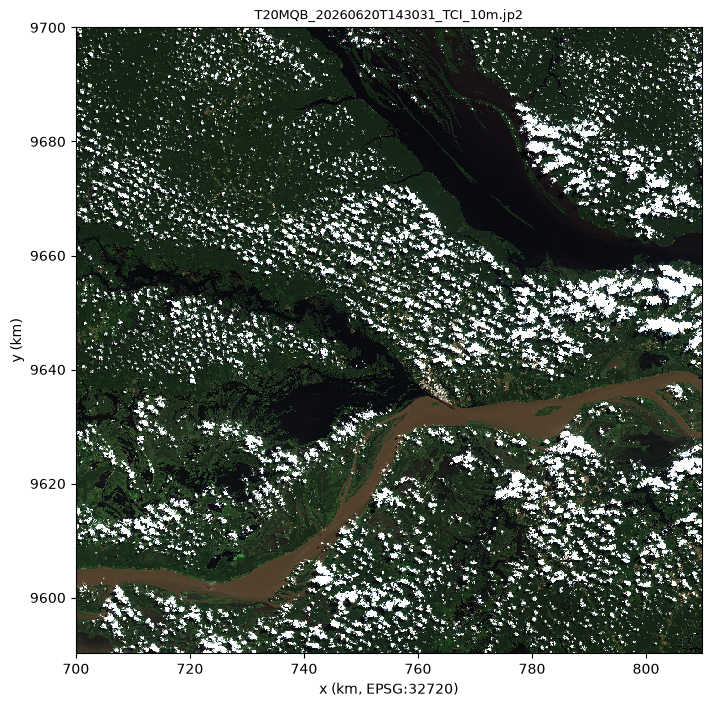

In [10]:
tci = sorted(OUTPUT_DIR.rglob("*_TCI_10m.jp2"))
plot_optical(tci[0]);

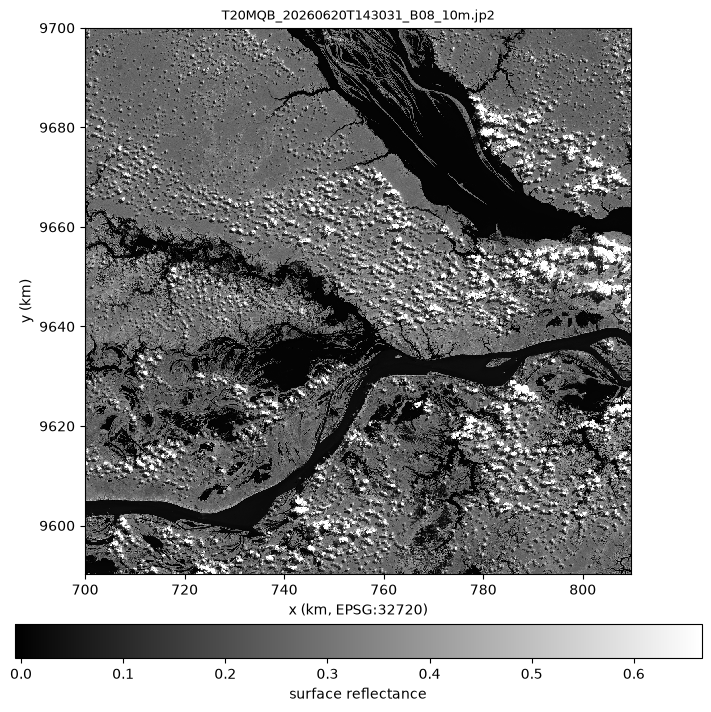

In [9]:
plot_optical(next(OUTPUT_DIR.rglob("*_B08_10m.jp2")));


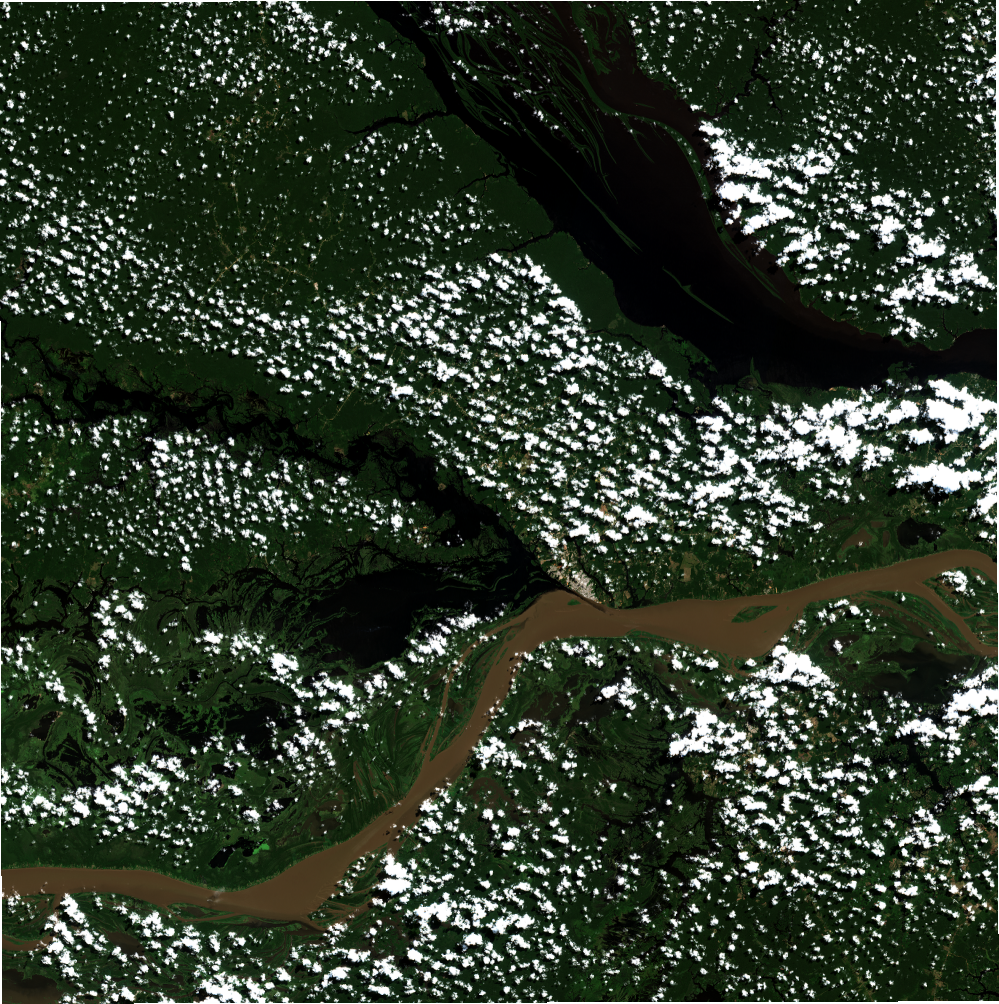

In [10]:
optical_map(tci)   # one layer per file; toggle them with the control in the top-right corner